## 04 Analysis of Results in Tarifverbund Schwyz

In [11]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os

stop_places = gpd.read_file(
    '../data/stop-places-schwyz/stop-places-schwyz-with-buffers.gpkg', 
    layer = 'stop_buffers',
    columns = ['Name', 'Nummer', 'buffer_timeseries', 'geometry']
)

stop_places.head()

/opt/anaconda3/envs/gda/lib/python3.13/site-packages/pyogrio/raw.py:198: RuntimeWarning: This version of GeoPackage user_version=0x000028A0 (10400, v1.4.0) on '../data/stop-places-schwyz/stop-places-schwyz-with-buffers.gpkg' may only be partially supported
  return ogr_read(


,Name,Nummer,buffer_timeseries,geometry
0,"Vitznau, Unterwilen",8577219,"[{""time"": ""2026-04-15T02:51:00Z"", ""buffer"": 52...",POINT (2678424 1208199)
1,"Weggis, Lützelau",8592427,"[{""time"": ""2026-04-15T02:52:00Z"", ""buffer"": 52...",POINT (2677775 1208686)
2,"Weggis, Lorbeerweg",8595630,NO TRANSFERS,POINT (2677367 1208708)
3,Gersau (See),8508468,NO TRANSFERS,POINT (2682717 1204972)
4,"Gersau, Schiffstation",8505671,"[{""time"": ""2026-04-15T02:54:00Z"", ""buffer"": 26...",POINT (2682727 1204989)


Total Stops: 486
Stops without Service: 66
Stops without Transfer: 254
Stops with Possible Transfers: 166


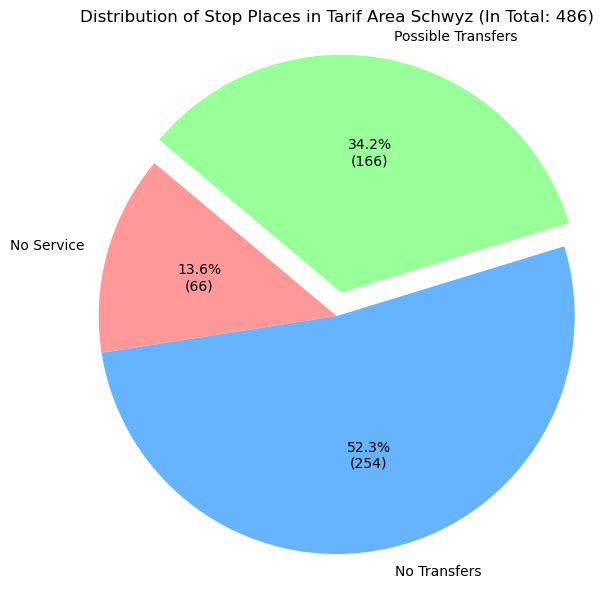

In [12]:
# Stats for stops without service, transfers and stops with possible transfers
total_stops = len(stop_places)
stops_without_service = len(stop_places[stop_places['buffer_timeseries']=='NO SERVICE'])
stops_without_transfer = len(stop_places[stop_places['buffer_timeseries']=='NO TRANSFERS'])
stops_with_transfers = total_stops - stops_without_service - stops_without_transfer

# Print the results
print(f"Total Stops: {total_stops}")
print(f"Stops without Service: {stops_without_service}")
print(f"Stops without Transfer: {stops_without_transfer}")
print(f"Stops with Possible Transfers: {stops_with_transfers}")

# Function to format the labels to show both count and percentage
def label_format(pct, allvals):
    absolute = int(round(pct/100.* np.sum(allvals)))
    return f"{pct:.1f}%\n({absolute:d})"

# Create the pie chart
plt.figure(figsize=(6,6))
plt.pie([stops_without_service, stops_without_transfer, stops_with_transfers], 
        explode=(0, 0, 0.1), 
        labels=['No Service', 'No Transfers', 'Possible Transfers'], 
        colors=['#ff9999','#66b3ff','#99ff99'], 
        autopct=lambda pct: label_format(pct, [stops_without_service, stops_without_transfer, stops_with_transfers]), 
        startangle=140)

plt.title(f'Distribution of Stop Places in Tarif Area Schwyz (In Total: {total_stops})')
plt.axis('equal')
plt.tight_layout()
# plt.savefig('stops_statistics_pie_chart.png')
plt.show()

In [13]:
stop_places_active = stop_places[
    (stop_places['buffer_timeseries'] != 'NO SERVICE') & 
    (stop_places['buffer_timeseries'] != 'NO TRANSFERS')
].copy()
stop_places_active.reset_index(drop=True, inplace=True)

In [14]:
stop_places_active['buffer_timeseries'] = stop_places_active['buffer_timeseries'].apply(json.loads)
df_long = stop_places_active.explode('buffer_timeseries')
df_unpacked = pd.concat([
    df_long.drop(columns=['buffer_timeseries']).reset_index(drop=True),
    pd.json_normalize(df_long['buffer_timeseries']).reset_index(drop=True)
], axis=1)
df_unpacked['buffer'] = df_unpacked['buffer'] / 60

df_unpacked['time'] = pd.to_datetime(df_unpacked['time'])
df_unpacked['buffer'] = pd.to_numeric(df_unpacked['buffer'])

In [15]:
bins = [0, 1, 3, 5, 10, 20, float('inf')]
labels = ['<1m', '1-3m', '3-5m', '5-10m', '10-20m', '20m+']
df_unpacked['buffer_category'] = pd.cut(df_unpacked['buffer'], bins=bins, labels=labels, include_lowest=True)

# create per-stop summary table
# This counts how many times each stop falls into each buffer category
stop_histogram = pd.crosstab(
    index=[df_unpacked['Nummer'], df_unpacked['Name'], df_unpacked['geometry']], 
    columns=df_unpacked['buffer_category']
)

stop_histogram.sort_values(by='<1m', ascending=False, inplace=True)
stop_histogram

,,buffer_category,<1m,1-3m,3-5m,5-10m,10-20m,20m+
Nummer,Name,geometry,,,,,,
8505095,"Schwyz, Zentrum",POINT (2692193 1208507),160,130,32,46,12,0
8505094,"Schwyz, Bahnhof",POINT (2690725 1209108),107,43,33,7,8,3
8577430,"Ibach, Mythen Center",POINT (2691974 1207892),92,25,37,98,13,0
8577206,"Küssnacht am Rigi, Hauptplatz",POINT (2676136 1214967),76,86,40,66,34,0
8573756,"Einsiedeln, Bahnhof",POINT (2699091 1220493),65,8,16,40,25,1
...,...,...,...,...,...,...,...,...
8573774,"Gross, Grossbach",POINT (2701673 1218836),0,6,0,0,6,36
8573773,"Gross, Nügüetli",POINT (2701409 1219605),0,0,0,0,0,41
8573769,"Bennau, Schwyzerbrugg",POINT (2696890 1222989),0,0,27,2,0,27


In [16]:
# Calculate Average and Median buffer for every stop
stop_performance = df_unpacked.groupby(['Nummer', 'Name', 'geometry'])['buffer'].agg(['mean', 'median', 'max', 'count'])

# Calculate Rush Hour performance per stop
rush_hour_mask = df_unpacked['time'].dt.hour.isin([7, 8, 16, 17])
stop_rush_performance = df_unpacked[rush_hour_mask].groupby(['Nummer', 'Name', 'geometry'])['buffer'].mean().rename('rush_hour_mean')

# Combine them into one master "Stop Analytics" dataframe
stop_analytics = stop_performance.join(stop_rush_performance)

stop_analytics

,,,mean,median,max,count,rush_hour_mean
Nummer,Name,geometry,,,,,
8503280,Steinerberg,POINT (2687122 1211879),619.631579,643.0,1047.0,19,463.000000
8503282,Rothenthurm,POINT (2693820 1217938),22.714286,16.0,61.0,63,22.000000
8503283,Einsiedeln,POINT (2699076 1220557),16.072464,11.0,304.0,69,10.500000
8503284,Biberbrugg,POINT (2697374 1223620),5.882051,4.0,30.0,195,5.863636
8503285,Schindellegi-Feusisberg,POINT (2696327 1225830),11.090909,8.0,50.0,143,10.424242
...,...,...,...,...,...,...,...
8592419,"Schwyz, St. Martinstrasse",POINT (2692309 1208673),44.064516,25.0,181.0,31,106.000000
8592427,"Weggis, Lützelau",POINT (2677775 1208686),419.435897,416.5,870.0,78,318.157895
8592430,"Weggis, Paradiesweg",POINT (2675553 1209510),85.759615,17.0,549.0,104,45.173913


In [17]:
# Create an hourly map for each stop
# Rows = Stops, Columns = Hours of the day
stop_hourly_map = df_unpacked.pivot_table(
    index='Name', 
    columns=df_unpacked['time'].dt.hour, 
    values='buffer', 
    aggfunc='mean'
)

stop_hourly_map

time,2,3,4,5,6,7,8,9,10,11,...,14,15,16,17,18,19,20,21,22,23
Name,,,,,,,,,,,,,,,,,,,,,
Altmatt,NaN,1007.500000,960.666667,901.333333,836.000000,776.000000,716.000000,656.000000,596.000000,536.000000,...,356.000000,296.000000,236.000000,176.000000,116.000000,70.000000,NaN,NaN,NaN,NaN
"Arth, Aazopf",35.0,20.571429,19.750000,19.375000,19.375000,19.375000,19.375000,19.375000,19.375000,19.375000,...,19.375000,19.375000,19.375000,19.375000,19.375000,10.000000,NaN,NaN,NaN,NaN
"Arth, Am See",33.0,19.375000,19.000000,18.625000,18.625000,18.625000,18.625000,18.625000,18.625000,18.625000,...,18.625000,18.625000,18.625000,18.625000,18.625000,6.666667,NaN,NaN,NaN,NaN
"Arth, Chäppeli",35.0,20.857143,20.000000,19.625000,19.625000,19.625000,19.625000,19.625000,19.625000,19.625000,...,19.625000,19.625000,19.625000,19.625000,19.625000,10.250000,NaN,NaN,NaN,NaN
"Arth, Dorf",30.0,17.714286,17.285714,16.857143,16.857143,16.857143,16.857143,16.857143,16.857143,16.857143,...,16.857143,16.857143,16.857143,16.857143,16.857143,8.000000,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Willerzell, Erlen",NaN,126.000000,NaN,40.666667,70.000000,126.000000,66.000000,29.500000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Willerzell, Grüene Aff",NaN,108.000000,48.000000,118.500000,169.000000,NaN,49.000000,10.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Willerzell, Kirche",NaN,13.000000,27.333333,17.400000,28.000000,77.000000,32.750000,12.750000,19.750000,77.000000,...,31.000000,16.000000,19.750000,19.750000,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# Export stop_histogram to GeoJSON in Web Mercator
stop_histogram_gdf = gpd.GeoDataFrame(stop_histogram.reset_index(), geometry='geometry')
os.makedirs('../data/output', exist_ok=True)
stop_histogram_gdf.to_crs('EPSG:3857').to_file('../data/output/stop_histogram_schwyz.geojson', driver='GeoJSON')
print("Exported stop_histogram_schwyz.geojson to ../data/output/ in Web Mercator (EPSG:3857)")

Exported stop_histogram_schwyz.geojson to ../data/output/ in Web Mercator (EPSG:3857)
